# Housing affordability: from the world to Europe, 1975–2025

**Team:** Akshat Dayal, Bhavini Manot, Bo De Roeck

**Course:** AI Methods I – Day 1: Data cleaning and EDA

## 0. Introduction

**Use case:** When house prices grow faster than incomes, buying a home gets harder and cities respond with smaller flats and higher density. We study this from macro to micro.

**Roadmap**
- **Part A – Macro (26 countries):** we load, check, clean and explore the full dataset.
- **Bridge:** we show why Europe needs a closer look.
- **Part B – Micro (17 European countries):** we zoom into Europe with its own checks, analysis and three questions.
- **Part C – Together:** write the overall conclusions.

### Tools
We load the libraries (ready-made tools) we need: pandas for tables, numpy for maths, matplotlib and seaborn for charts.

In [1]:
# Import the packages
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fixed seed so results are the same every time
random_state = 42

# PART A – MACRO: all 26 countries

### A1. Load the data
We read the CSV with all 26 countries from the data folder.

In [2]:
df = pd.read_csv("../data/accessibilit-economica-alloggi-26-paesi-1975-2025.csv")
df.head()

,country,iso,year,house_price_index,personal_disposable_income,real_house_price_index,real_personal_disposable_income,affordability_proxy
0,Australia,AUS,1975,2.83,7.19,21.89,55.72,39.29
1,Australia,AUS,1976,3.19,8.11,21.65,55.04,39.34
2,Australia,AUS,1977,3.48,8.91,21.43,54.88,39.05
3,Australia,AUS,1978,3.75,9.85,21.28,55.91,38.06
4,Australia,AUS,1979,4.20,10.80,21.75,55.94,38.88


### A1. First look

**Size**

In [3]:
df.shape

(1326, 8)

**Columns and types**

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1326 entries, 0 to 1325
Data columns (total 8 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   country                          1326 non-null   str    
 1   iso                              1326 non-null   str    
 2   year                             1326 non-null   int64  
 3   house_price_index                1326 non-null   float64
 4   personal_disposable_income       1326 non-null   float64
 5   real_house_price_index           1326 non-null   float64
 6   real_personal_disposable_income  1326 non-null   float64
 7   affordability_proxy              1326 non-null   float64
dtypes: float64(5), int64(1), str(2)
memory usage: 83.0 KB


**Missing values**

In [5]:
df.isna().sum()

country                            0
iso                                0
year                               0
house_price_index                  0
personal_disposable_income         0
real_house_price_index             0
real_personal_disposable_income    0
affordability_proxy                0
dtype: int64

**Duplicates**

In [6]:
df.duplicated().sum()

np.int64(0)

**Quick statistics**

In [7]:
df.describe()

,year,house_price_index,personal_disposable_income,real_house_price_index,real_personal_disposable_income,affordability_proxy
count,1326.000000,1326.000000,1326.000000,1326.000000,1326.000000,1326.000000
mean,2000.000000,45.946131,46.018469,73.161395,73.154487,102.955437
std,14.725155,33.065122,28.423394,30.650240,18.670035,60.875057
min,1975.000000,0.000000,0.000000,16.140000,16.190000,37.300000
25%,1987.000000,16.982500,22.335000,49.110000,58.662500,75.522500
50%,2000.000000,42.140000,44.825000,71.760000,73.460000,96.020000
75%,2013.000000,69.872500,68.815000,97.075000,88.962500,109.497500
max,2025.000000,162.300000,106.490000,181.470000,107.730000,725.910000


**Which countries and years**

In [8]:
print(df.columns.tolist())

['country', 'iso', 'year', 'house_price_index', 'personal_disposable_income', 'real_house_price_index', 'real_personal_disposable_income', 'affordability_proxy']


In [9]:
df.groupby("country")["year"].count()

country
Australia      51
Belgium        51
Canada         51
Colombia       51
Croatia        51
Denmark        51
Finland        51
France         51
Germany        51
Ireland        51
Israel         51
Italy          51
Japan          51
Luxembourg     51
Netherlands    51
New Zealand    51
Norway         51
Portugal       51
S. Africa      51
S. Korea       51
Slovenia       51
Spain          51
Sweden         51
Switzerland    51
UK             51
US             51
Name: year, dtype: int64

In [10]:
df[["house_price_index", "personal_disposable_income", "affordability_proxy"]].head()

,house_price_index,personal_disposable_income,affordability_proxy
0,2.83,7.19,39.29
1,3.19,8.11,39.34
2,3.48,8.91,39.05
3,3.75,9.85,38.06
4,4.20,10.80,38.88


### A2. Dataset card

| | |
|---|---|
| **Name** | Housing affordability, 26 countries, 1975–2025 |
| **Source** | Kaggle: "Forecasting housing affordability to 2035" (https://www.kaggle.com/code/tolstoyjustin/forecasting-housing-affordability-to-2035/output). Column names match the Dallas Fed International House Price Database, the likely original source. |
| **What one row is** | One country in one year |
| **Size** | 1,326 rows × 8 columns (26 countries × 51 years, 1975–2025), balanced panel, no gaps |
| **Licence** | CC BY-SA 4.0 |

**Limitations**
- **Indexes, not money:** we can compare trends over time, not price levels between countries.
- **Hidden zeros:** 31 zeros in `house_price_index` and 30 in `personal_disposable_income` (Israel, Croatia, Slovenia, early years), caused by hyperinflation plus rounding to 2 decimals.
- **Early data for some countries may be estimated**, e.g. Croatia has values from 1975, before independence (1991).
- **National averages only:** hides city-level differences (e.g. Barcelona vs rest of Spain).
- **The proxy ignores mortgage interest rates**, which strongly affect real affordability.
- **2025 may be incomplete or estimated.**
- **Mostly high-income countries:** results don't represent the whole world.

### A2. Data dictionary

| Column | Meaning |
|---|---|
| `country` | Country name |
| `iso` | 3-letter country code (e.g. ESP = Spain) |
| `year` | Year |
| `house_price_index` | House prices (not adjusted for inflation) |
| `personal_disposable_income` | What people earn after tax (not adjusted for inflation) |
| `real_house_price_index` | House prices, adjusted for inflation |
| `real_personal_disposable_income` | Income after tax, adjusted for inflation |
| `affordability_proxy` | House prices ÷ income × 100. **Higher = harder to afford** |

### A3. Detect problems with the data

In [11]:
df_clean = df.copy()

**Duplicates**

In [12]:
print(df_clean.duplicated().sum())
print(df_clean.duplicated(subset=["country", "year"]).sum())

0
0


**Missing values: hidden zeros** (an index can't be 0)

In [13]:
cols = ["house_price_index", "personal_disposable_income",
        "real_house_price_index", "real_personal_disposable_income"]
(df_clean[cols] <= 0).sum()

house_price_index                  31
personal_disposable_income         30
real_house_price_index              0
real_personal_disposable_income     0
dtype: int64

**Data types**

In [14]:
df_clean.dtypes

country                                str
iso                                    str
year                                 int64
house_price_index                  float64
personal_disposable_income         float64
real_house_price_index             float64
real_personal_disposable_income    float64
affordability_proxy                float64
dtype: object

In [15]:
print(df_clean["iso"].unique())
print(df_clean["country"].unique())

<StringArray>
['AUS', 'BEL', 'CAN', 'CHE', 'DEU', 'DNK', 'ESP', 'FIN', 'FRA', 'GBR', 'IRL',
 'ITA', 'JPN', 'KOR', 'LUX', 'NLD', 'NOR', 'NZL', 'SWE', 'USA', 'ZAF', 'HRV',
 'ISR', 'SVN', 'COL', 'PRT']
Length: 26, dtype: str
<StringArray>
[  'Australia',     'Belgium',      'Canada', 'Switzerland',     'Germany',
     'Denmark',       'Spain',     'Finland',      'France',          'UK',
     'Ireland',       'Italy',       'Japan',    'S. Korea',  'Luxembourg',
 'Netherlands',      'Norway', 'New Zealand',      'Sweden',          'US',
   'S. Africa',     'Croatia',      'Israel',    'Slovenia',    'Colombia',
    'Portugal']
Length: 26, dtype: str


In [16]:
df_clean["country"] = df_clean["country"].str.strip().astype("category")
df_clean["iso"] = df_clean["iso"].str.strip().str.upper()

**Outliers: year-on-year % change**

In [17]:
df_clean = df_clean.sort_values(["country", "year"])
df_clean["hpi_change_pct"] = df_clean.groupby("country", observed=True)["house_price_index"].pct_change() * 100

big_jumps = df_clean[df_clean["hpi_change_pct"].abs() > 30]
big_jumps[["country", "year", "hpi_change_pct"]]

,country,year,hpi_change_pct
108,Canada,1981,38.110749
1230,Colombia,1981,31.884058
1238,Colombia,1989,31.140351
1243,Colombia,1994,31.424376
1085,Croatia,1989,inf
1086,Croatia,1990,500.000000
1087,Croatia,1991,233.333333
1088,Croatia,1992,1160.000000
1089,Croatia,1993,782.539683
1090,Croatia,1994,36.735612


**Flat values**

In [18]:
flat = df_clean[df_clean["hpi_change_pct"] == 0]
flat.groupby("country", observed=True)["year"].agg(["count", "min", "max"])

,count,min,max
country,,,
Israel,1,1980,1980
S. Korea,1,1985,1985
Sweden,1,1983,1983


**Boxplot of affordability_proxy per country**

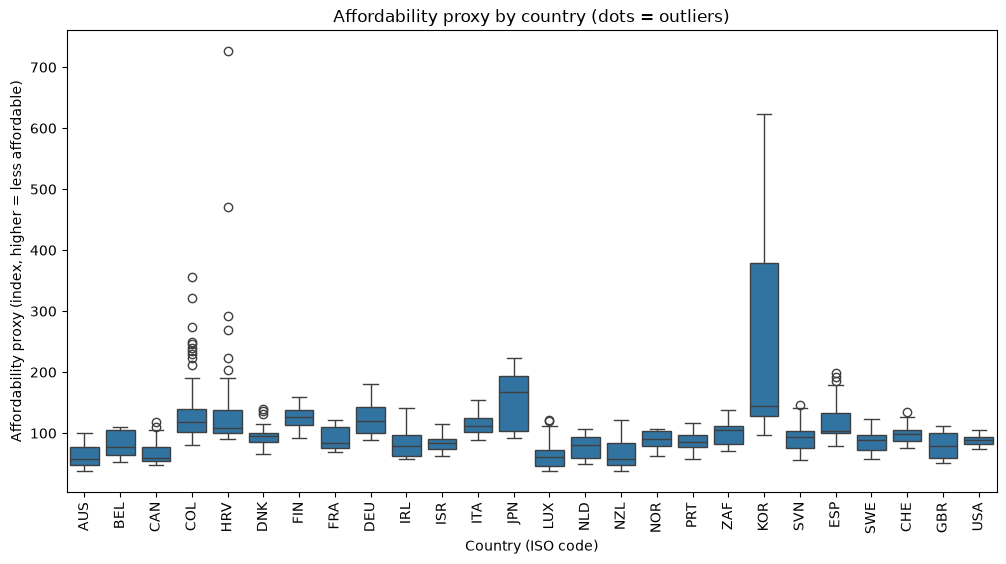

In [19]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean, x="iso", y="affordability_proxy")
plt.xticks(rotation=90)
plt.title("Affordability proxy by country (dots = outliers)")
plt.xlabel("Country (ISO code)")
plt.ylabel("Affordability proxy (index, higher = less affordable)")
os.makedirs("../figures", exist_ok=True)
plt.savefig("../figures/A_00_boxplot_by_country.png", dpi=150, bbox_inches="tight")
plt.show()

### A4. Cleaning

We rebuild affordability from the real (inflation-adjusted) columns, which have no zeros, and drop the broken nominal columns.

In [20]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates(subset=["country", "year"])
df_clean["country"] = df_clean["country"].str.strip().astype("category")
df_clean["iso"] = df_clean["iso"].str.strip().str.upper()

df_clean["affordability"] = (df_clean["real_house_price_index"]
                             / df_clean["real_personal_disposable_income"] * 100)

df_clean = df_clean.sort_values(["country", "year"])
df_clean["real_hpi_change_pct"] = (df_clean.groupby("country", observed=True)["real_house_price_index"]
                                   .pct_change() * 100)
df_clean["outlier_flag"] = df_clean["real_hpi_change_pct"].abs() > 30

df_clean = df_clean.drop(columns=["house_price_index", "personal_disposable_income",
                                  "affordability_proxy"])

print("Cleaned:", df_clean.shape)

Cleaned: (1326, 8)


### A4. Data cleaning log

**Dataset:** Housing affordability, 26 countries, 1975–2025 (1,326 rows × 8 columns)

### 1. Duplicates
- Exact duplicate rows: **0**
- Duplicate country-year pairs: **0**
- Every country has exactly 51 years → balanced panel
- **Action:** none needed

### 2. Missing values
- NaN values: **0** in all columns
- But hidden problem: **31 zeros** in `house_price_index` and **30 zeros** in
  `personal_disposable_income` (a price or income index can't be 0)
- Affected: early years of **Israel, Croatia, Slovenia**
- **Cause:** hyperinflation (Israel 1980s, Yugoslavia late 1980s–early 90s) made
  early nominal values tiny; rounding to 2 decimals turned them into 0.00
- **Action:** rebuilt affordability from the real (inflation-adjusted) columns,
  which contain no zeros; dropped the broken nominal columns

### 3. Data types
- Numbers stored as float/int, text as string → correct
- 26 countries and 26 ISO codes, consistent spelling, no extra spaces
- **Action:** trimmed text, converted `country` to category

### 4. Outliers
- **38** country-years with nominal price jumps above 30%
- Most were **fake**: caused by the rounding zeros (e.g. `inf`, +1,160%, +1,500%
  for Croatia and Slovenia; Croatia's affordability proxy above 700)
- Some are **real** housing booms: Canada 1981, Italy 1981, Netherlands 1976–77,
  Ireland 1998
- South Korea's high values are real: incomes grew much faster than house prices

### 5. Extra decision
- Croatia and Slovenia are marked unreliable before 1995: hyperinflation distorted values even after the zeros ended (visible as a ~500% spike in the boxplot and in Figure 2).

### A5. Feature engineering

Feature engineering means creating new, more useful columns from the existing ones.
This dataset has **no free-text columns** (no listing titles to extract bedrooms from),
so the hidden information sits in the **country codes**, in **how values change over
time**, and in the **problems found during cleaning**.

### 4.1 Region from the country code (text → category)
The ISO code (e.g. `ESP`, `KOR`) was mapped to a `region` (Southern Europe, Nordic,
Asia...). Countries in the same region often share housing systems and economic cycles.

### 4.2 Relative position in each country's history
Affordability values are **indexes, not money**, so 150 can be normal in one country
and extreme in another. Like the floor ratio, each year is placed relative to its own country:
- `affordability_position`: 0 = the country's most affordable year, 1 = its least affordable
- `affordability_vs_own_avg`: 100 = normal for that country, 130 = 30% less affordable than usual

### 4.3 Change over time
Housing is a time series, so this year depends on last year:
- `decade`
- `real_income_change_pct`: yearly change in income after inflation
- `affordability_lag1`, `affordability_lag2`: last year and two years ago
- `affordability_3yr_avg`: smoothed 3-year trend
- **Target for Day 2:** `affordability_next`, next year's affordability

### 4.4 Clean categories and flags from the cleaning log
- Country names written out in full ("S. Africa" → "South Africa", "UK" → "United Kingdom"...)
- Each cleaning-log finding became a True/False column:

| Cleaning log finding | Feature | Count |
|---|---|---|
| Hidden zeros (hyperinflation + rounding) | `nominal_zero` | 31 rows |
| Countries affected (Israel, Croatia, Slovenia) | `hyperinflation_country` | 3 countries |
| Early years unreliable | `data_reliable` | reliable from: Croatia 1995, Israel 1979, Slovenia 1995 |
| Real price jumps above +30% | `price_shock_up` | 4 booms |
| Real price drops below −30% | `price_shock_down` | 1 crash |
| 2008 financial crisis | `gfc_period` | 2008–2012 |
| 2025 may be incomplete | `is_latest_year` | 2025 |

### 4.5 Detective work: what is `affordability_proxy`?
**Hypothesis:** `affordability_proxy` = house_price_index ÷ personal_disposable_income × 100.

**Test:** our calculation ÷ their column should be ≈ 1.
- Nominal ratio: median 1.000
- Real (inflation-adjusted) ratio: median 1.000 (100% of rows within 1%)

**Conclusion:** the proxy is price ÷ income, and the real columns give the same ratio,
because inflation cancels out. So for the rows where rounding produced zeros, we did
**not guess** the affordability: we **calculated it exactly** from the real columns.
Rows with impossible affordability (≤ 0) after the fix: 0

In [21]:
# ===== STEP 4: FEATURE ENGINEERING =====

df_clean = df_clean.sort_values(["country", "year"]).reset_index(drop=True)
c = df_clean["country"].astype(str)
g = df_clean.groupby("country", observed=True)

# --- A. Text → category: region from ISO code ---
region_map = {
    "AUS": "Oceania", "NZL": "Oceania",
    "CAN": "North America", "USA": "North America",
    "COL": "Latin America", "JPN": "Asia", "KOR": "Asia",
    "ISR": "Middle East", "ZAF": "Africa",
    "DNK": "Nordic", "FIN": "Nordic", "NOR": "Nordic", "SWE": "Nordic",
    "ESP": "Southern Europe", "ITA": "Southern Europe", "PRT": "Southern Europe",
    "HRV": "Central/Eastern Europe", "SVN": "Central/Eastern Europe",
    "BEL": "Western Europe", "CHE": "Western Europe", "DEU": "Western Europe",
    "FRA": "Western Europe", "GBR": "Western Europe", "IRL": "Western Europe",
    "LUX": "Western Europe", "NLD": "Western Europe",
}
df_clean["region"] = df_clean["iso"].map(region_map)

# --- B. Time features ---
df_clean["decade"] = (df_clean["year"] // 10) * 10
df_clean["gfc_period"] = df_clean["year"].between(2008, 2012).astype(int)
df_clean["is_latest_year"] = (df_clean["year"] == df_clean["year"].max()).astype(int)

# --- C. Change and history features ---
df_clean["real_income_change_pct"] = g["real_personal_disposable_income"].pct_change() * 100
df_clean["affordability_lag1"] = g["affordability"].shift(1)
df_clean["affordability_lag2"] = g["affordability"].shift(2)
df_clean["affordability_3yr_avg"] = g["affordability"].transform(lambda s: s.rolling(3).mean())

# --- D. Features from the cleaning log ---
zero_rows = df[(df["house_price_index"] <= 0) | (df["personal_disposable_income"] <= 0)]
zero_keys = set(zip(zero_rows["country"], zero_rows["year"]))
last_zero_year = zero_rows.groupby("country")["year"].max()

df_clean["nominal_zero"] = [int((ct, y) in zero_keys) for ct, y in zip(c, df_clean["year"])]
df_clean["hyperinflation_country"] = c.isin(last_zero_year.index).astype(int)
df_clean["data_reliable"] = (df_clean["year"] > c.map(last_zero_year).fillna(0)).astype(int)
df_clean["price_shock_up"] = (df_clean["real_hpi_change_pct"] > 30).astype(int)
df_clean["price_shock_down"] = (df_clean["real_hpi_change_pct"] < -30).astype(int)

own_avg = g["affordability"].transform("mean")
df_clean["affordability_vs_own_avg"] = df_clean["affordability"] / own_avg * 100

# --- E. Target for Day 2: next year's affordability ---
df_clean["affordability_next"] = g["affordability"].shift(-1)

# ===== CHECKS =====
print("Columns now:", df_clean.shape[1])
print("Regions missing:", df_clean["region"].isna().sum())
print("Hidden-zero rows:", df_clean["nominal_zero"].sum())
print("Hyperinflation countries:", sorted(c[df_clean["hyperinflation_country"] == 1].unique()))
print("Reliable from:", (last_zero_year + 1).to_dict())
print("Unreliable rows:", (df_clean["data_reliable"] == 0).sum())
print("Booms:", df_clean["price_shock_up"].sum(), "| Crashes:", df_clean["price_shock_down"].sum())
df_clean.head()

Columns now: 23
Regions missing: 0
Hidden-zero rows: 31
Hyperinflation countries: ['Croatia', 'Israel', 'Slovenia']
Reliable from: {'Croatia': 1989, 'Israel': 1979, 'Slovenia': 1988}
Unreliable rows: 31
Booms: 4 | Crashes: 1


,country,iso,year,real_house_price_index,real_personal_disposable_income,affordability,real_hpi_change_pct,outlier_flag,region,decade,...,affordability_lag1,affordability_lag2,affordability_3yr_avg,nominal_zero,hyperinflation_country,data_reliable,price_shock_up,price_shock_down,affordability_vs_own_avg,affordability_next
0,Australia,AUS,1975,21.89,55.72,39.285714,NaN,False,Oceania,1970,...,NaN,NaN,NaN,0,0,1,0,0,61.781980,39.335029
1,Australia,AUS,1976,21.65,55.04,39.335029,-1.096391,False,Oceania,1970,...,39.285714,NaN,NaN,0,0,1,0,0,61.859534,39.048834
2,Australia,AUS,1977,21.43,54.88,39.048834,-1.016166,False,Oceania,1970,...,39.335029,39.285714,39.223192,0,0,1,0,0,61.409455,38.061170
3,Australia,AUS,1978,21.28,55.91,38.061170,-0.699953,False,Oceania,1970,...,39.048834,39.335029,38.815011,0,0,1,0,0,59.856222,38.880944
4,Australia,AUS,1979,21.75,55.94,38.880944,2.208647,False,Oceania,1970,...,38.061170,39.048834,38.663649,0,0,1,0,0,61.145425,42.938456


In [22]:
# --- F. Relative position in each country's history (0 = most affordable, 1 = least) ---
low = g["affordability"].transform("min")
high = g["affordability"].transform("max")
df_clean["affordability_position"] = (df_clean["affordability"] - low) / (high - low)
df_clean["affordability_position"] = df_clean["affordability_position"].where(
    df_clean["affordability_position"].between(0, 1))

# --- G. Write country names in full (done LAST so the flags above still match) ---
name_map = {"S. Africa": "South Africa", "S. Korea": "South Korea",
            "UK": "United Kingdom", "US": "United States"}
df_clean["country"] = df_clean["country"].astype(str).replace(name_map).astype("category")

**Check: what is affordability_proxy?**

In [23]:
import numpy as np

nominal = df["house_price_index"] / df["personal_disposable_income"] * 100
real = df["real_house_price_index"] / df["real_personal_disposable_income"] * 100

ratio_nominal = (nominal / df["affordability_proxy"]).replace([np.inf, -np.inf], np.nan)
ratio_real = (real / df["affordability_proxy"]).replace([np.inf, -np.inf], np.nan)

print(f"Nominal / proxy -> median ratio {ratio_nominal.median():.3f}")
print(f"Real / proxy    -> median ratio {ratio_real.median():.3f}")
print(f"Real ratio within 1% of 1: {ratio_real.dropna().between(0.99, 1.01).mean():.1%}")
print(f"Impossible affordability (<= 0): {(df_clean['affordability'] <= 0).sum()}")

Nominal / proxy -> median ratio 1.000
Real / proxy    -> median ratio 1.000
Real ratio within 1% of 1: 100.0%
Impossible affordability (<= 0): 0


**Croatia and Slovenia before 1995 are also unreliable** (hyperinflation distorted values even after the zeros ended). We update the flag and compute the own-average using only reliable years.

In [24]:
# hyperinflation distortion continued after the zeros: exclude until 1995
early_distortion = df_clean["iso"].isin(["HRV", "SVN"]) & (df_clean["year"] < 1995)
df_clean.loc[early_distortion, "data_reliable"] = 0
print("Unreliable rows now:", (df_clean["data_reliable"] == 0).sum())

Unreliable rows now: 44


In [25]:
own_avg = (df_clean[df_clean["data_reliable"] == 1]
           .groupby("country", observed=True)["affordability"].mean())
df_clean["affordability_vs_own_avg"] = df_clean["affordability"] / df_clean["country"].map(own_avg).astype(float) * 100

### A6. Exploration (26 countries)

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
fig_dir = Path("..") / "figures"
fig_dir.mkdir(exist_ok=True)

# use only trustworthy years for the charts (excludes the hyperinflation years)
plot_df = df_clean[df_clean["data_reliable"] == 1].copy()
print("Rows used for charts:", len(plot_df))

Rows used for charts: 1282


**Descriptive statistics**

In [27]:
plot_df[["affordability", "affordability_vs_own_avg",
         "real_hpi_change_pct", "real_income_change_pct"]].describe().round(1)

,affordability,affordability_vs_own_avg,real_hpi_change_pct,real_income_change_pct
count,1282.0,1282.0,1259.0,1259.0
mean,102.3,100.0,1.7,1.6
std,57.9,27.0,6.8,3.0
min,37.3,37.5,-25.3,-15.9
25%,75.8,80.5,-2.2,0.1
50%,96.0,97.3,1.4,1.5
75%,109.5,114.9,5.6,2.9
max,622.8,250.8,30.6,42.6


**Figure 1: How has affordability changed over time?**

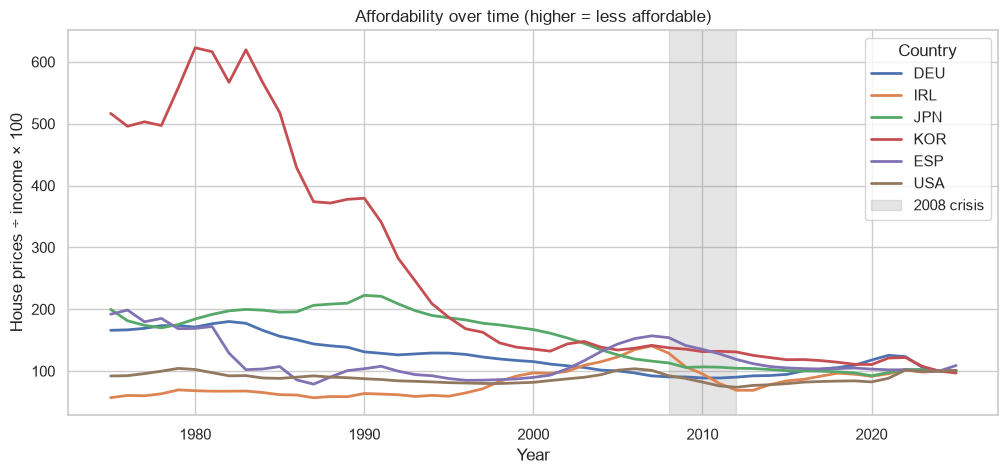

In [28]:
pick = ["ESP", "USA", "DEU", "KOR", "IRL", "JPN"]

plt.figure(figsize=(12, 5))
sns.lineplot(data=plot_df[plot_df["iso"].isin(pick)],
             x="year", y="affordability", hue="iso", linewidth=2)
plt.axvspan(2008, 2012, color="grey", alpha=0.2, label="2008 crisis")
plt.title("Affordability over time (higher = less affordable)")
plt.xlabel("Year")
plt.ylabel("House prices ÷ income × 100")
plt.legend(title="Country")
plt.savefig(fig_dir / "A_01_affordability_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 2: Every country compared to its own normal**

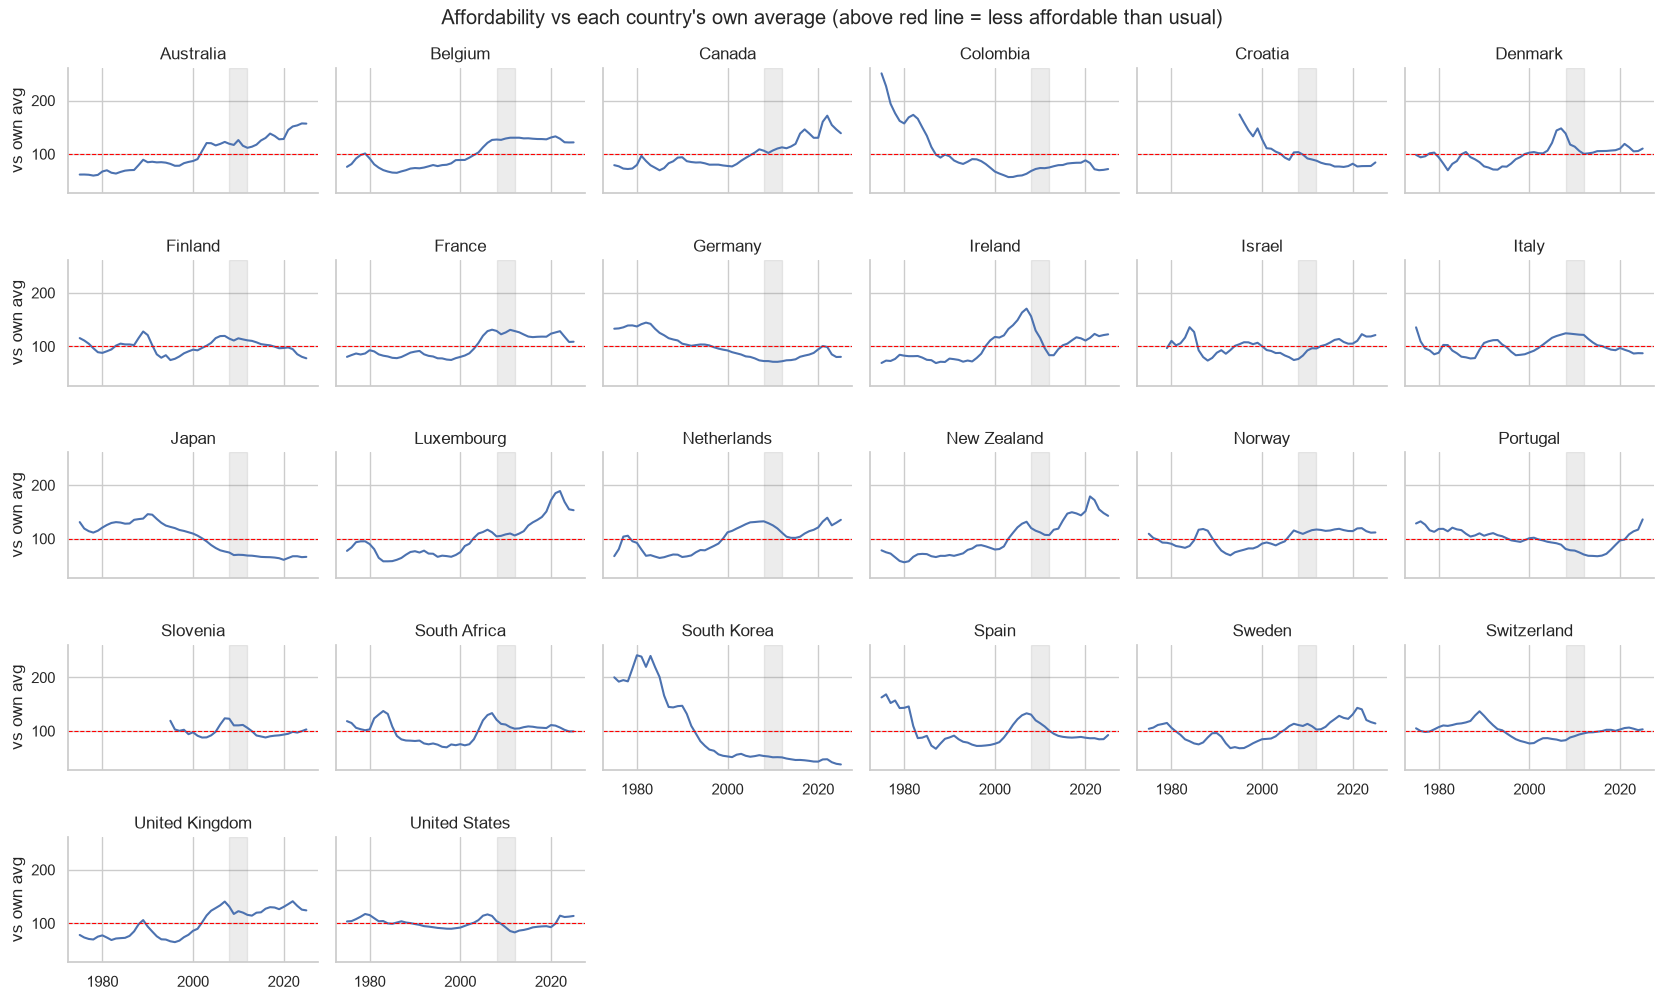

In [29]:
fg = sns.relplot(data=plot_df, x="year", y="affordability_vs_own_avg",
                 col="country", col_wrap=6, kind="line",
                 height=2, aspect=1.4, linewidth=1.5)
for ax in fg.axes.flat:
    ax.axhline(100, color="red", linestyle="--", linewidth=0.8)   # 100 = normal
    ax.axvspan(2008, 2012, color="grey", alpha=0.15)
fg.set_titles("{col_name}")
fg.set_axis_labels("", "vs own avg")
fg.fig.suptitle("Affordability vs each country's own average (above red line = less affordable than usual)", y=1.02)
fg.savefig(fig_dir / "A_02_all_countries_vs_own_avg.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 3: Which regions are least affordable?**

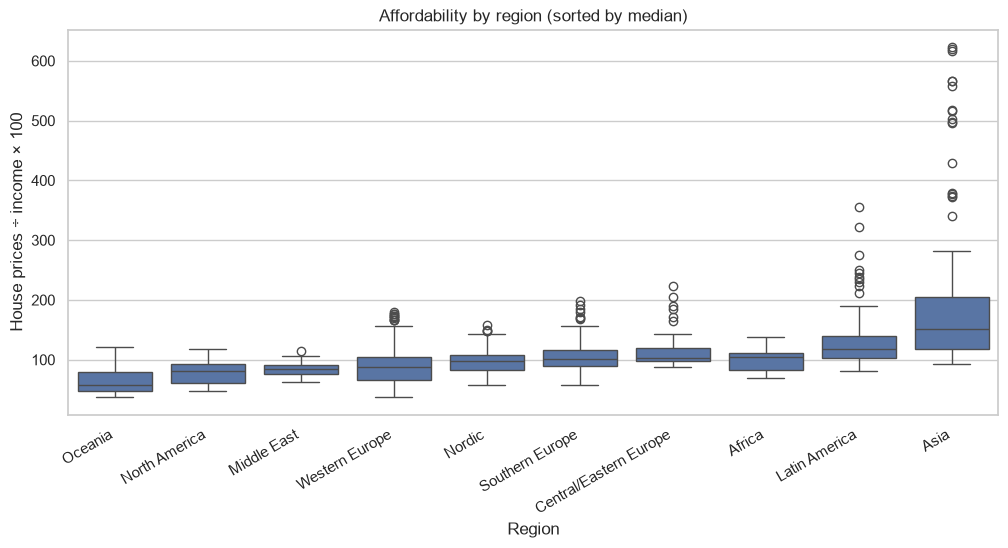

In [30]:
order = plot_df.groupby("region")["affordability"].median().sort_values().index

plt.figure(figsize=(12, 5))
sns.boxplot(data=plot_df, x="region", y="affordability", order=order)
plt.xticks(rotation=30, ha="right")
plt.title("Affordability by region (sorted by median)")
plt.ylabel("House prices ÷ income × 100")
plt.xlabel("Region")
plt.savefig(fig_dir / "A_03_affordability_by_region.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 4: Heatmap of country × decade**

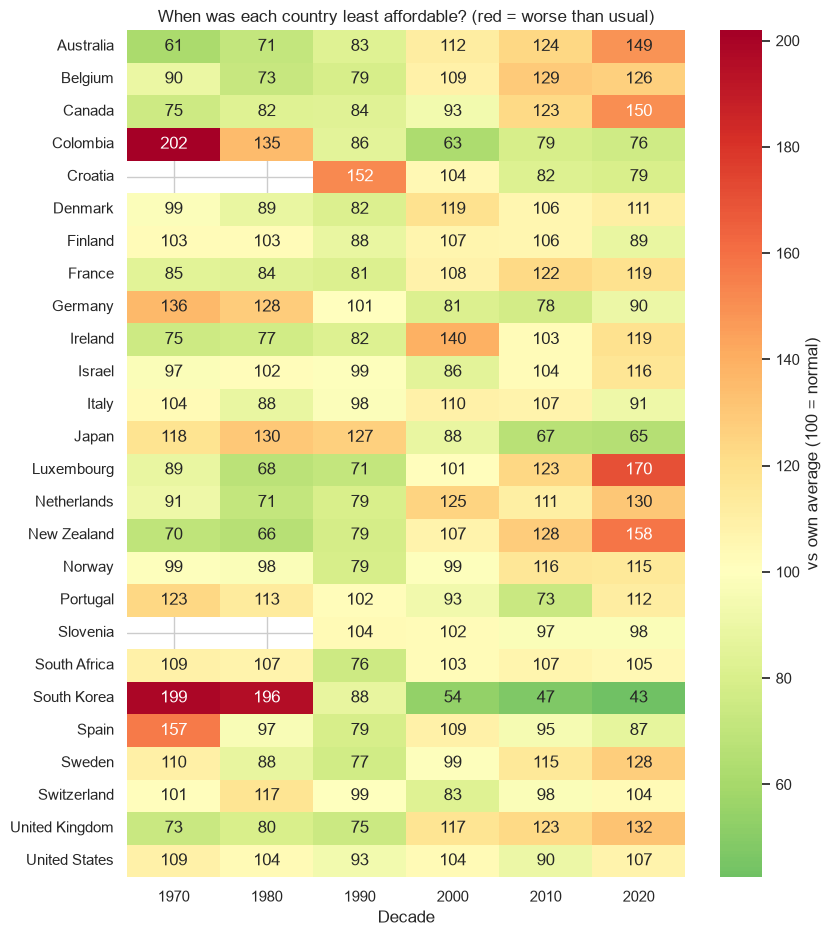

In [31]:
table = plot_df.pivot_table(index="country", columns="decade",
                            values="affordability_vs_own_avg",
                            aggfunc="mean", observed=True)

plt.figure(figsize=(9, 11))
sns.heatmap(table, cmap="RdYlGn_r", center=100, annot=True, fmt=".0f",
            cbar_kws={"label": "vs own average (100 = normal)"})
plt.title("When was each country least affordable? (red = worse than usual)")
plt.xlabel("Decade")
plt.ylabel("")
plt.savefig(fig_dir / "A_04_heatmap_country_decade.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 5: Do prices grow faster than incomes?**

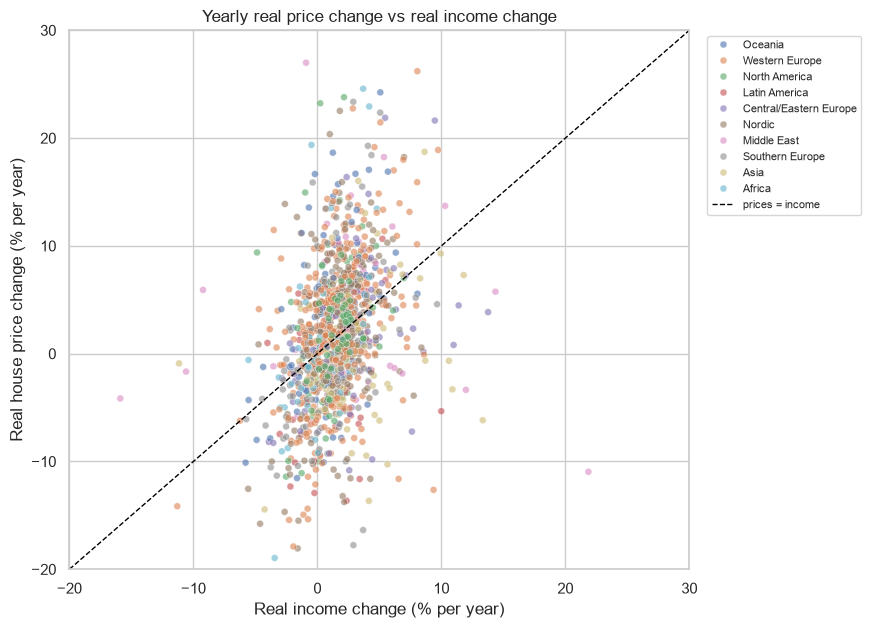

In [32]:
plt.figure(figsize=(8, 7))
sns.scatterplot(data=plot_df, x="real_income_change_pct", y="real_hpi_change_pct",
                hue="region", alpha=0.6, s=25)
lims = [-20, 30]
plt.plot(lims, lims, color="black", linestyle="--", linewidth=1, label="prices = income")
plt.xlim(lims); plt.ylim(lims)
plt.title("Yearly real price change vs real income change")
plt.xlabel("Real income change (% per year)")
plt.ylabel("Real house price change (% per year)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.savefig(fig_dir / "A_05_prices_vs_income.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 6: How big are yearly price changes?**

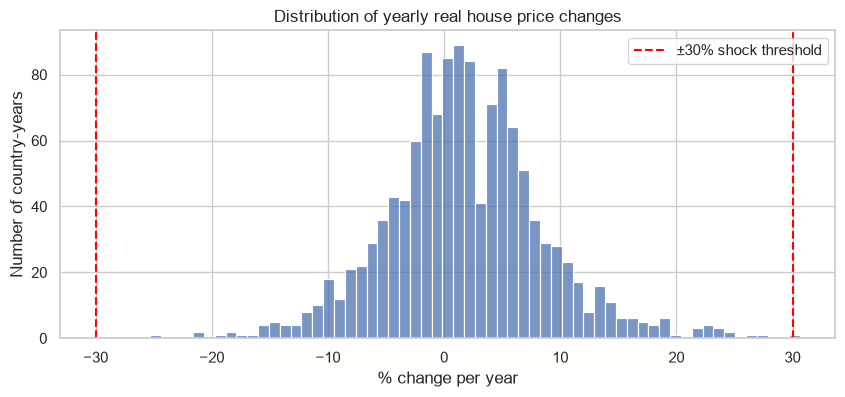

In [33]:
plt.figure(figsize=(10, 4))
sns.histplot(plot_df["real_hpi_change_pct"].dropna(), bins=60)
plt.axvline(30, color="red", linestyle="--", label="±30% shock threshold")
plt.axvline(-30, color="red", linestyle="--")
plt.title("Distribution of yearly real house price changes")
plt.xlabel("% change per year")
plt.ylabel("Number of country-years")
plt.legend()
plt.savefig(fig_dir / "A_06_price_change_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 7: Which features predict next year?**

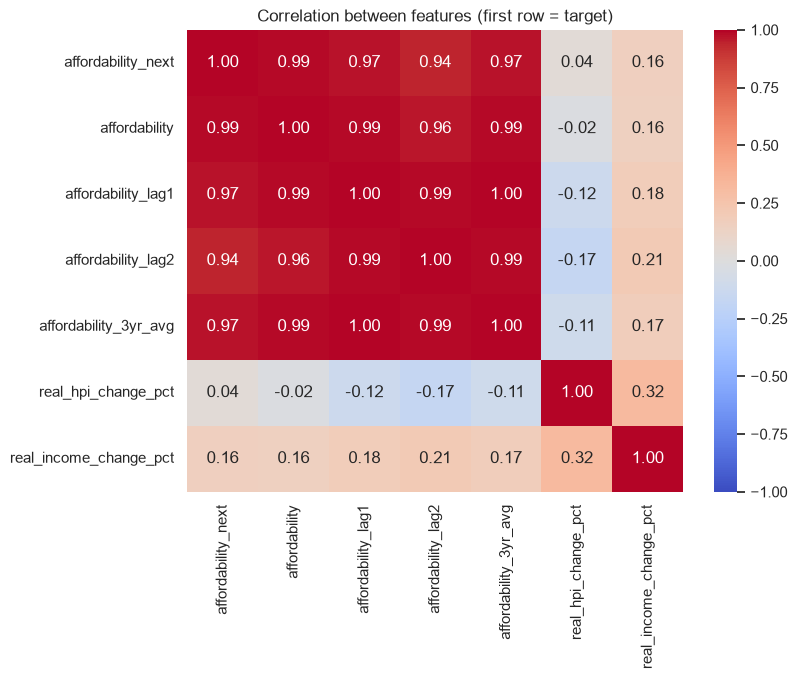

In [34]:
num_cols = ["affordability_next", "affordability", "affordability_lag1",
            "affordability_lag2", "affordability_3yr_avg",
            "real_hpi_change_pct", "real_income_change_pct"]

plt.figure(figsize=(8, 6))
sns.heatmap(plot_df[num_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between features (first row = target)")
plt.savefig(fig_dir / "A_07_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

### A6. Macro findings

1. **Rising unaffordability since 2000:** Luxembourg (170), New Zealand (158),
   Canada (150), Australia (149), UK (132) and the Netherlands (130) are far above
   their historical average in the 2020s.
2. **Improving affordability:** South Korea (199 → 43), Japan (130 → 65, after the
   1990 bubble) and Colombia (202 → 76): incomes grew much faster than prices.
3. **2008 crisis:** clearly visible for Ireland (peak 140 in the 2000s, then a crash);
   smaller peaks before 2008 in Spain, Denmark and the US.
4. **Most stable:** United States, close to 100 in every decade.
5. **Limit of national data:** Spain shows 87 in the 2020s (more affordable than
   usual), which hides strong city-level pressure such as in Barcelona.
6. **Data quality found through the chart:** Croatia showed a ~500% spike in the
   early 1990s (hyperinflation). Croatia and Slovenia before 1995 were marked
   unreliable and excluded.

# BRIDGE – Why zoom into Europe?
We compare the median yearly growth of real house prices and real incomes since 2000 in Europe and in the rest of the world.

               House prices   Incomes
group                                
Europe             1.955930  1.276543
Rest of world      1.558771  1.644476


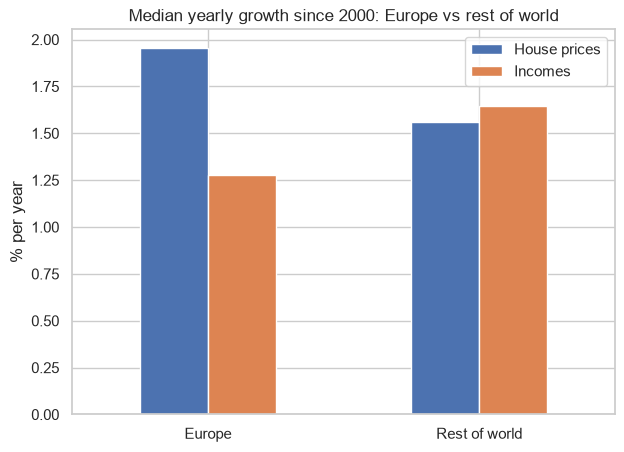

In [35]:
eu_iso = ["BEL", "HRV", "DNK", "FIN", "FRA", "DEU", "IRL", "ITA", "LUX",
          "NLD", "NOR", "PRT", "SVN", "ESP", "SWE", "CHE", "GBR"]
recent_all = df_clean[df_clean["year"] >= 2000].copy()
recent_all["group"] = np.where(recent_all["iso"].isin(eu_iso), "Europe", "Rest of world")
summary = recent_all.groupby("group")[["real_hpi_change_pct", "real_income_change_pct"]].median()
summary.columns = ["House prices", "Incomes"]
print(summary)

summary.plot(kind="bar", figsize=(7, 5))
plt.title("Median yearly growth since 2000: Europe vs rest of world")
plt.xlabel("")
plt.ylabel("% per year")
plt.xticks(rotation=0)
plt.savefig("../figures/BRIDGE_europe_vs_world.png", dpi=150, bbox_inches="tight")
plt.show()

Outside Europe, incomes kept up with house prices since 2000 (prices +1.56% per year, incomes +1.64%). In Europe, prices grew much faster than incomes (+1.96% vs +1.28%). So the affordability problem is strongest in Europe, which is why Part B zooms in.

# PART B – MICRO: 17 European countries

### B1. Europe
We start to analyse only the 17 European countries.

In [36]:
# List of the European countries we want to keep
europe = ["Belgium", "Croatia", "Denmark", "Finland", "France", "Germany",
          "Ireland", "Italy", "Luxembourg", "Netherlands", "Norway", "Portugal",
          "Slovenia", "Spain", "Sweden", "Switzerland", "UK"]

# Keep only rows where the country is in our list
df = df[df["country"].isin(europe)]

# Check the size: (rows, columns)
print(df.shape)

(867, 8)


### B2. Europe: data quality check and cleaning

#### B2.1 Duplicates

In [37]:
# Count rows that are exact copies
print(df.duplicated().sum())

# Count if the same country and year appear twice
print(df.duplicated(subset=["country", "year"]).sum())

0
0


No duplicates. Every country has one row for each year.

#### B2.2 Missing values

In [38]:
# Count empty values in each column
print(df.isna().sum())

# Count zeros in each column
print((df == 0).sum())

country                            0
iso                                0
year                               0
house_price_index                  0
personal_disposable_income         0
real_house_price_index             0
real_personal_disposable_income    0
affordability_proxy                0
dtype: int64
country                             0
iso                                 0
year                                0
house_price_index                  27
personal_disposable_income         26
real_house_price_index              0
real_personal_disposable_income     0
affordability_proxy                 0
dtype: int64


In [39]:
# Which countries and years have a zero house price?
zeros = df[df["house_price_index"] == 0]
print(zeros[["country", "year"]])

       country  year
1071   Croatia  1975
1072   Croatia  1976
1073   Croatia  1977
1074   Croatia  1978
1075   Croatia  1979
1076   Croatia  1980
1077   Croatia  1981
1078   Croatia  1982
1079   Croatia  1983
1080   Croatia  1984
1081   Croatia  1985
1082   Croatia  1986
1083   Croatia  1987
1084   Croatia  1988
1173  Slovenia  1975
1174  Slovenia  1976
1175  Slovenia  1977
1176  Slovenia  1978
1177  Slovenia  1979
1178  Slovenia  1980
1179  Slovenia  1981
1180  Slovenia  1982
1181  Slovenia  1983
1182  Slovenia  1984
1183  Slovenia  1985
1184  Slovenia  1986
1185  Slovenia  1987


In [40]:
# The real columns still have values for the same years
croatia = df[df["country"] == "Croatia"]
print(croatia[["year", "house_price_index", "real_house_price_index"]].head(16))

      year  house_price_index  real_house_price_index
1071  1975               0.00                   63.78
1072  1976               0.00                   72.46
1073  1977               0.00                   81.48
1074  1978               0.00                   84.57
1075  1979               0.00                   82.93
1076  1980               0.00                   75.34
1077  1981               0.00                   68.50
1078  1982               0.00                   69.87
1079  1983               0.00                   63.25
1080  1984               0.00                   53.29
1081  1985               0.00                   53.98
1082  1986               0.00                   52.35
1083  1987               0.00                   62.05
1084  1988               0.00                   69.23
1085  1989               0.01                   56.14
1086  1990               0.06                   63.52


We found 27 zeros in house_price_index (Croatia 1975–1988 and Slovenia 1975–1987). An index can't really be 0. These countries had hyperinflation in the 1980s, so the old values became very small and were rounded to 0.00 when the data was saved with 2 decimals.

Decision: we change these zeros to missing values (NaN) instead of deleting the rows, because the real (inflation-adjusted) columns for those years still have proper values. For the rest of the analysis we use the real columns.

In [41]:
# Replace the fake zeros with NaN (missing)
df["house_price_index"] = df["house_price_index"].replace(0, np.nan)
df["personal_disposable_income"] = df["personal_disposable_income"].replace(0, np.nan)

# Check: zeros should now be gone
print((df == 0).sum())

country                            0
iso                                0
year                               0
house_price_index                  0
personal_disposable_income         0
real_house_price_index             0
real_personal_disposable_income    0
affordability_proxy                0
dtype: int64


#### B2.3 Data types

In [42]:
# Type of each column
print(df.dtypes)

country                                str
iso                                    str
year                                 int64
house_price_index                  float64
personal_disposable_income         float64
real_house_price_index             float64
real_personal_disposable_income    float64
affordability_proxy                float64
dtype: object


In [43]:
# Each country should appear only once in this list
print(df["country"].unique())
print(df["country"].nunique())

<StringArray>
[    'Belgium', 'Switzerland',     'Germany',     'Denmark',       'Spain',
     'Finland',      'France',          'UK',     'Ireland',       'Italy',
  'Luxembourg', 'Netherlands',      'Norway',      'Sweden',     'Croatia',
    'Slovenia',    'Portugal']
Length: 17, dtype: str
17


All types are correct: text for country and code, whole numbers for year, decimals for the indices. There are 17 country names and no spelling mistakes, so nothing needs fixing here.

#### B2.4 Outliers
We look for unusually high values of affordability_proxy with a boxplot, and check if they are mistakes or real events.

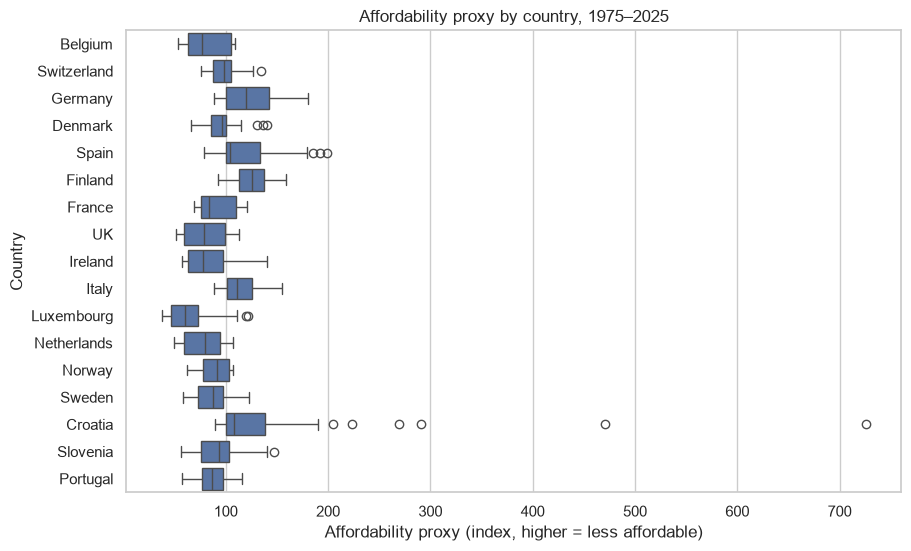

In [44]:
os.makedirs("../figures", exist_ok=True)   # make the figures folder if it isn't there
# Boxplot of affordability for each country
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="affordability_proxy", y="country")
plt.title("Affordability proxy by country, 1975–2025")
plt.xlabel("Affordability proxy (index, higher = less affordable)")
plt.ylabel("Country")
plt.savefig("../figures/B_01_outliers_boxplot.png")
plt.show()

In [45]:
# Find values far above normal (IQR rule)
q1 = df["affordability_proxy"].quantile(0.25)
q3 = df["affordability_proxy"].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
print("Upper limit:", upper)

outliers = df[df["affordability_proxy"] > upper]
print(outliers.groupby("country")["year"].agg(["min", "max", "count"]))

Upper limit: 154.605
          min   max  count
country                   
Croatia  1991  2000     10
Finland  1989  1989      1
Germany  1975  1985     11
Italy    1975  1975      1
Spain    1975  2007      8


We found 31 values above the IQR upper limit (154.6), mostly Croatia 1991–2000, Germany 1975–1985 and Spain (including 2007).

These are not mistakes. They match real events: the war and hyperinflation in Croatia in the 1990s, the Spanish housing bubble before 2008, the Finnish bubble in 1989, and much lower incomes in the 1970s compared to today.

Decision: we keep all of them because they are real. We add a column that marks them, so we can leave them out later if needed (for example, for modelling on Day 2).

In [46]:
# Mark the outliers with True / False
df["is_outlier"] = df["affordability_proxy"] > upper

# Check how many are marked
print(df["is_outlier"].sum())

31


#### B2.5 New columns (feature engineering)
We created three new columns:
- price_growth: yearly % change in real house prices
- income_growth: yearly % change in real income
- gap: price_growth minus income_growth. If it is positive, house prices grew faster than incomes that year, so housing became harder to afford.

For architecture this is important: when prices keep growing faster than incomes, people can afford less space, which pushes cities towards smaller flats and higher density.

In [47]:
# Sort by country and year so each year follows the previous one
df = df.sort_values(["country", "year"])

# Yearly % change, calculated separately for each country
df["price_growth"] = df.groupby("country")["real_house_price_index"].pct_change() * 100
df["income_growth"] = df.groupby("country")["real_personal_disposable_income"].pct_change() * 100

# Gap: positive = prices grew faster than incomes
df["gap"] = df["price_growth"] - df["income_growth"]

# Look at the new columns for Spain
print(df[df["country"] == "Spain"][["year", "price_growth", "income_growth", "gap"]].tail(10))

     year  price_growth  income_growth       gap
347  2016      1.662283       2.820173 -1.157890
348  2017      0.848598       1.398301 -0.549703
349  2018      1.980503       1.368410  0.612093
350  2019      2.042665       1.140645  0.902020
351  2020     -1.143871       0.548370 -1.692242
352  2021     -0.039900       1.090759 -1.130660
353  2022     -1.486878      -1.598127  0.111249
354  2023     -1.256078       1.137892 -2.393970
355  2024      2.585146       2.280863  0.304282
356  2025      8.170000      -0.780000  8.950000


#### B2.6 Summary of cleaning decisions

| Check | What we found | What we did |
|---|---|---|
| Duplicates | None | Nothing needed |
| Missing values | No empty cells, but 27 fake zeros (Croatia and Slovenia, 1975–1988) | Changed them to NaN and used the real columns instead |
| Data types | All correct, 17 countries spelled one way | Nothing needed |
| Outliers | 31 very high values (Croatia 1990s, Spain 2007, Germany 1970s) | Kept them because they are real events, and marked them in is_outlier |
| New columns | – | Added price_growth, income_growth and gap |

### B3. Europe: exploratory data analysis

#### B3.1 Descriptive statistics
We look at the averages and spread of the main columns, using data from 2000 onwards.

In [48]:
# Statistics of the main columns
print(df[["real_house_price_index", "real_personal_disposable_income", "affordability_proxy", "price_growth", "income_growth", "gap"]].describe())

# Typical yearly growth since 2000
recent = df[df["year"] >= 2000]
print("Median price growth:", recent["price_growth"].median())
print("Median income growth:", recent["income_growth"].median())
print("Share of years where prices grew faster:", (recent["gap"] > 0).mean())

       real_house_price_index  real_personal_disposable_income  \
count              867.000000                       867.000000   
mean                72.296390                        74.220334   
std                 27.614585                        17.677069   
min                 16.140000                        19.430000   
25%                 51.040000                        60.315000   
50%                 70.930000                        75.170000   
75%                 94.970000                        89.210000   
max                146.070000                       104.730000   

       affordability_proxy  price_growth  income_growth         gap  
count           867.000000    850.000000     850.000000  850.000000  
mean             97.185525      1.862642       1.395248    0.467395  
std              37.857460      7.609665       4.101397    8.178067  
min              37.300000    -35.543486     -45.765065  -45.410798  
25%              76.830000     -2.109310      -0.073997

Since 2000, real house prices grew about 1.96% per year and real incomes about 1.28% per year in the median country. Prices grew faster than incomes in 57% of the years. The difference looks small, but it adds up every year. House price growth also jumps around much more than income growth.

#### B3.2 Univariate analysis
We look at how price growth and income growth are spread out.

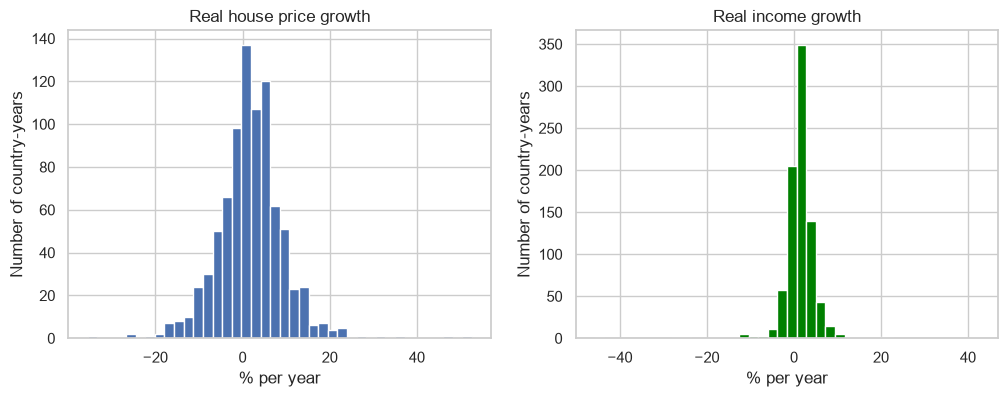

In [49]:
# Histograms: how often each growth value appears
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(df["price_growth"].dropna(), bins=40)
plt.title("Real house price growth")
plt.xlabel("% per year")
plt.ylabel("Number of country-years")

plt.subplot(1, 2, 2)
plt.hist(df["income_growth"].dropna(), bins=40, color="green")
plt.title("Real income growth")
plt.xlabel("% per year")
plt.ylabel("Number of country-years")

plt.savefig("../figures/B_02_distributions.png")
plt.show()

Income growth stays close to 1–2% most years. House price growth is much wider: some years prices jump more than 20%, and in crashes they fall a lot. So house prices are much less stable than incomes.

#### B3.3 Bivariate analysis
Do house prices go up when incomes go up? We plot one against the other.

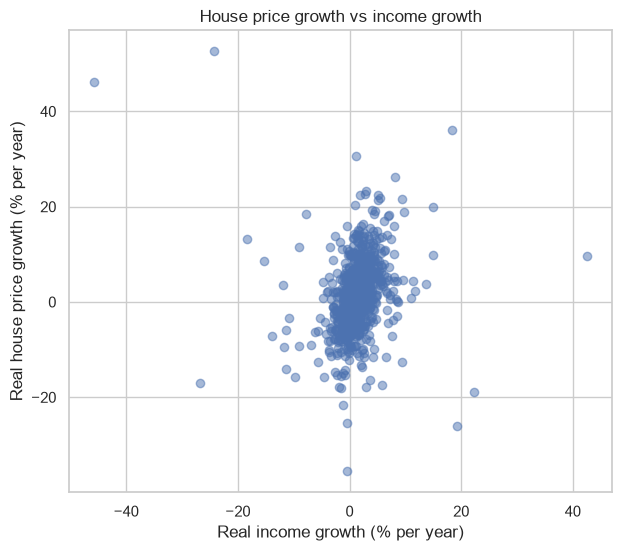

Correlation: 0.1257226823349293


In [50]:
# Scatter plot: each dot is one country in one year
plt.figure(figsize=(7, 6))
plt.scatter(df["income_growth"], df["price_growth"], alpha=0.5)
plt.title("House price growth vs income growth")
plt.xlabel("Real income growth (% per year)")
plt.ylabel("Real house price growth (% per year)")
plt.savefig("../figures/B_03_prices_vs_incomes.png")
plt.show()

print("Correlation:", df["income_growth"].corr(df["price_growth"]))

The dots form a cloud, not a line. The correlation is only about 0.13, which is very weak. This means house prices do not simply follow incomes from year to year. Other things, like interest rates, loans and how many houses are built, probably matter more, but they are not in this dataset.

#### B3.4 Grouped comparisons
We compare the average gap (price growth minus income growth) by decade.

decade
1970s    0.529329
1980s   -0.061600
1990s   -0.032180
2000s    2.093583
2010s   -0.170038
2020s    0.492460
Name: gap, dtype: float64


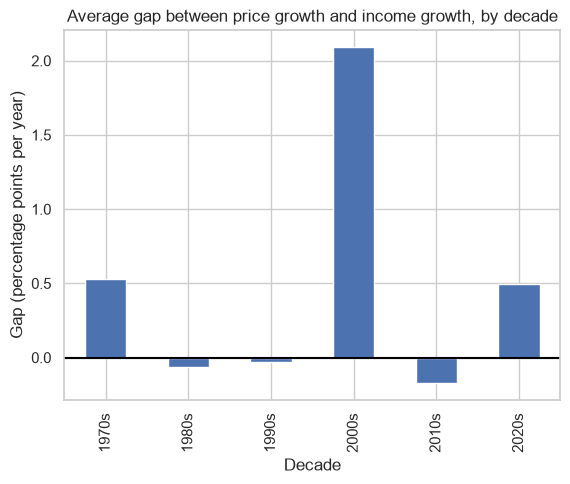

In [51]:
# Make a decade column, e.g. 2000s
df["decade"] = (df["year"] // 10 * 10).astype(str) + "s"

# Average gap per decade
gap_decade = df.groupby("decade")["gap"].mean()
print(gap_decade)

gap_decade.plot(kind="bar")
plt.title("Average gap between price growth and income growth, by decade")
plt.xlabel("Decade")
plt.ylabel("Gap (percentage points per year)")
plt.axhline(0, color="black")
plt.savefig("../figures/B_04_gap_by_decade.png")
plt.show()

The 2000s stand out: prices grew about 2.1 percentage points per year faster than incomes, which was the housing boom before the 2008 crisis. In the 2010s it went slightly negative, so housing became a bit more affordable after the crash. In the 2020s the gap is positive again (about 0.5), so affordability is getting worse again.

#### B3.5 Correlation
We check which numeric columns move together.

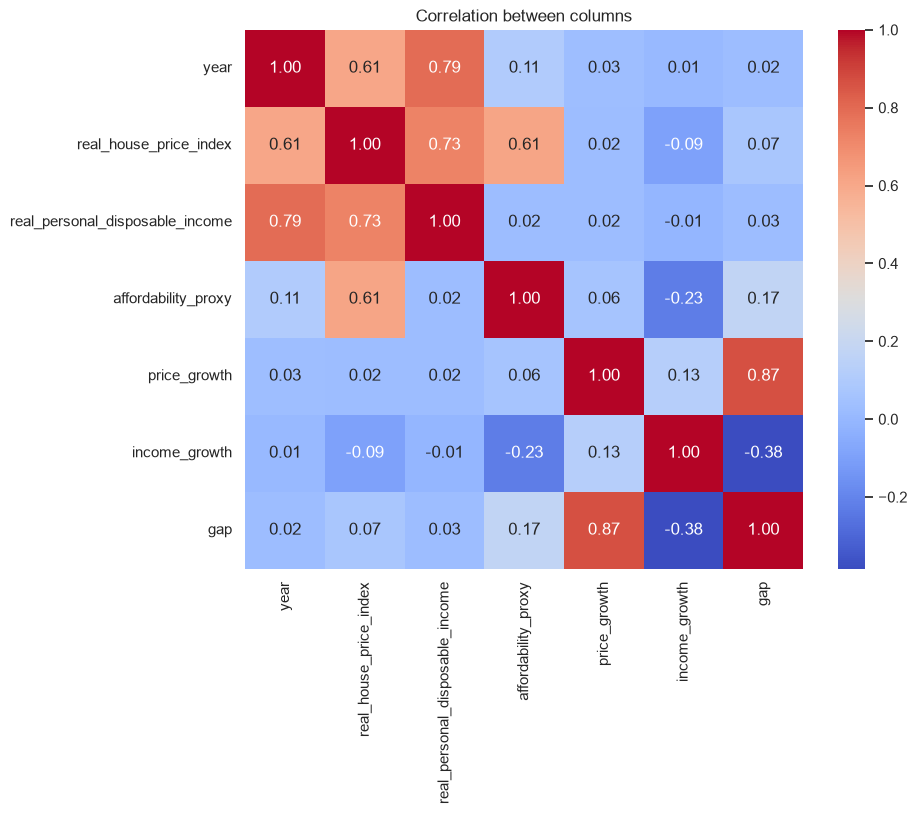

In [52]:
# Correlation heatmap
cols = ["year", "real_house_price_index", "real_personal_disposable_income", "affordability_proxy", "price_growth", "income_growth", "gap"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between columns")
plt.savefig("../figures/B_05_correlation.png")
plt.show()

affordability_proxy is linked to real house prices (0.61) but hardly to real income (0.02), so in this data affordability moves mainly with house prices. gap is strongly linked to price_growth (0.87), but that is expected because we calculated gap from it. Correlation does not mean causation: two things can move together without one causing the other. For example, year and income are linked (0.79) because economies grew over time, not because time causes income.

### B4. Three questions

#### B4.1 Question 1: Since 2000, where did housing become harder to afford?
We compare each country's affordability_proxy in 2025 with 2000.

country
Croatia        -33.851500
Finland        -17.177440
Germany        -12.957502
Italy           -1.656151
Ireland          4.108743
Slovenia         5.465877
Denmark          7.487127
Netherlands     20.858469
Spain           21.403118
Norway          22.875337
Switzerland     34.415154
Sweden          34.812569
Portugal        34.832503
France          35.336927
Belgium         36.963064
UK              44.308231
Luxembourg     104.929577
dtype: float64


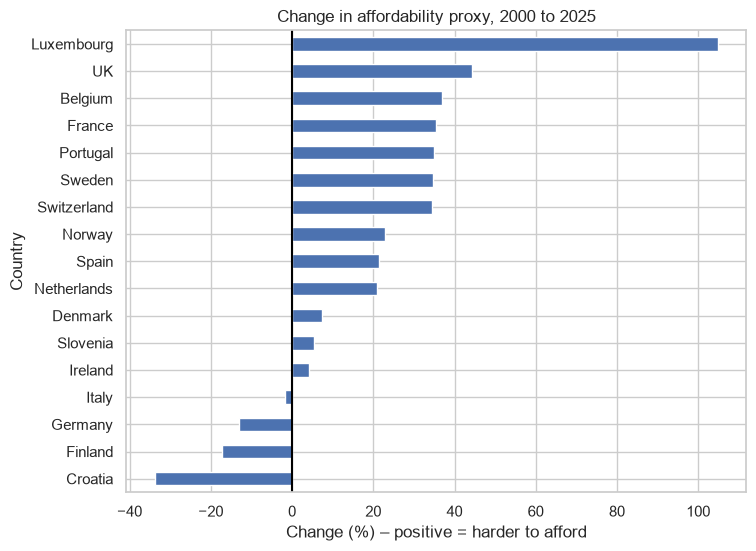

In [53]:
# Put years as columns, countries as rows
table = df.pivot(index="country", columns="year", values="affordability_proxy")

# % change from 2000 to 2025
change = (table[2025] / table[2000] - 1) * 100
change = change.sort_values()
print(change)

change.plot(kind="barh", figsize=(8, 6))
plt.title("Change in affordability proxy, 2000 to 2025")
plt.xlabel("Change (%) – positive = harder to afford")
plt.ylabel("Country")
plt.axvline(0, color="black")
plt.savefig("../figures/B_06_q1_change.png")
plt.show()

Housing became harder to afford in 13 of the 17 countries. Luxembourg is by far the worst (+105%), followed by the UK (+44%), Belgium (+37%) and France (+35%). Only four countries improved: Croatia (−34%), Finland (−17%), Germany (−13%) and Italy (−2%).

This matters for architecture because in countries like Luxembourg and the UK people can afford less space, which increases demand for smaller and denser housing.

Limits: we only compare two years, and national averages hide big differences between cities and rural areas.

#### B4.2 Question 2: Did the 2008 crisis make housing affordable again?
We follow affordability over time in Spain and Ireland (big housing bubbles) and Germany (no bubble).

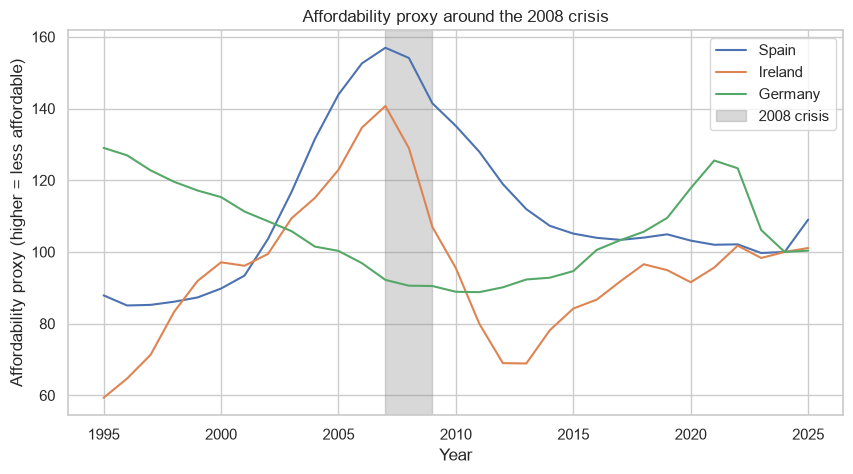

In [54]:
plt.figure(figsize=(10, 5))
for c in ["Spain", "Ireland", "Germany"]:
    one = df[(df["country"] == c) & (df["year"] >= 1995)]
    plt.plot(one["year"], one["affordability_proxy"], label=c)

plt.axvspan(2007, 2009, color="grey", alpha=0.3, label="2008 crisis")
plt.title("Affordability proxy around the 2008 crisis")
plt.xlabel("Year")
plt.ylabel("Affordability proxy (higher = less affordable)")
plt.legend()
plt.savefig("../figures/B_07_q2_crisis.png")
plt.show()

Spain and Ireland reached a peak in 2007 (about 157 and 141), then fell sharply after the crisis. Ireland dropped to about 69 by 2013, roughly half. Spain fell more slowly, reaching about 103 only in 2020. Germany did the opposite: it became cheaper in the 2000s and then rose to about 126 in 2021, before falling again.

So the crisis did make housing more affordable in the bubble countries, but only for some years. By 2025 all three are back around 100–109.

Limits: we can see the change but not the reasons. Interest rates and the number of new houses built are not in the data.

#### B4.3 Question 3: Is Spain becoming harder to afford than other European countries?
We compare Spain with the median of all 17 countries.

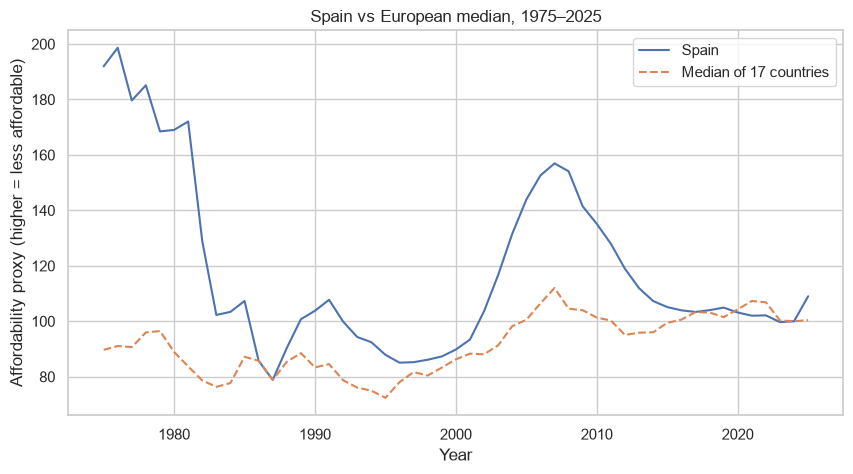

In [55]:
# Median of all countries per year
median = df.groupby("year")["affordability_proxy"].median()
spain = df[df["country"] == "Spain"]

plt.figure(figsize=(10, 5))
plt.plot(spain["year"], spain["affordability_proxy"], label="Spain")
plt.plot(median.index, median.values, label="Median of 17 countries", linestyle="--")
plt.title("Spain vs European median, 1975–2025")
plt.xlabel("Year")
plt.ylabel("Affordability proxy (higher = less affordable)")
plt.legend()
plt.savefig("../figures/B_08_q3_spain.png")
plt.show()

Spain has been less affordable than the European median for most of the period. The difference was largest in the late 1970s (around 200 vs 90) and again during the housing bubble, peaking in 2007 (157 vs 112). After the crisis Spain moved close to the median, but in 2025 it is above it again (109 vs 100), after prices jumped about 8% in one year while incomes fell.

For us in Barcelona this suggests that housing pressure in Spain is rising again. But this is a national average: big cities and tourist areas are probably much worse, and the data does not include rents.

### B5. Europe findings
- Housing became harder to afford in 13 of 17 European countries between 2000 and 2025. Luxembourg is the worst (+105%), followed by the UK (+44%) and Belgium (+37%). Croatia, Finland, Germany and Italy improved.
- Since 2000, real house prices grew about 1.96% per year and real incomes about 1.28% per year in the median country. Prices grew faster in 57% of the years.
- From year to year, house price growth is only weakly linked to income growth (correlation 0.13), so other factors drive prices.
- The 2000s were the boom decade: prices grew about 2.1 points per year faster than incomes. The 2008 crisis brought affordability down in Spain and Ireland, but only for some years.
- In the 2020s prices are again growing faster than incomes, and Spain had a big jump in 2025.

# PART C – Together: save the data and conclude

**Save:** we save the clean 26-country table, the clean Europe table, and a model-ready file for Day 2.

In [56]:
final_columns = [
    # target (what we will predict on Day 2)
    "affordability_next",
    # identity and time
    "country", "iso", "region", "year", "decade",
    # core values
    "affordability", "real_house_price_index", "real_personal_disposable_income",
    # change and history
    "real_hpi_change_pct", "real_income_change_pct",
    "affordability_lag1", "affordability_lag2", "affordability_3yr_avg",
    # flags from the cleaning log
    "nominal_zero", "hyperinflation_country", "data_reliable",
    "price_shock_up", "price_shock_down", "gfc_period", "is_latest_year",
    # relative to each country's whole history -> exploration only (leakage!)
    "affordability_position", "affordability_vs_own_avg",
]

# keep only the columns that exist (in case one step was skipped)
missing = [col for col in final_columns if col not in df_clean.columns]
print("Not found (skipped):", missing)

df_final = df_clean[[col for col in final_columns if col in df_clean.columns]].copy()
df_final.info()

Not found (skipped): []
<class 'pandas.DataFrame'>
RangeIndex: 1326 entries, 0 to 1325
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype   
---  ------                           --------------  -----   
 0   affordability_next               1300 non-null   float64 
 1   country                          1326 non-null   category
 2   iso                              1326 non-null   str     
 3   region                           1326 non-null   str     
 4   year                             1326 non-null   int64   
 5   decade                           1326 non-null   int64   
 6   affordability                    1326 non-null   float64 
 7   real_house_price_index           1326 non-null   float64 
 8   real_personal_disposable_income  1326 non-null   float64 
 9   real_hpi_change_pct              1300 non-null   float64 
 10  real_income_change_pct           1300 non-null   float64 
 11  affordability_lag1               1300 non-null   float64

In [57]:
leakage_cols = ["affordability_position", "affordability_vs_own_avg"]

model_df = (
    df_final[df_final["data_reliable"] == 1]            # 1. only trustworthy years
    .drop(columns=leakage_cols + ["country"], errors="ignore")   # 2. no future info, no text name
    .dropna()                                           # 3. rows with all lags AND a target
    .copy()
)

# 4. region as 0/1 columns, True/False as 0/1, so a model can read everything as numbers
model_df = pd.get_dummies(model_df, columns=["region"], dtype=int)
bool_cols = model_df.select_dtypes("bool").columns
model_df[bool_cols] = model_df[bool_cols].astype(int)

print("Model-ready shape:", model_df.shape)
print("Years covered:", model_df["year"].min(), "-", model_df["year"].max())
print("Countries:", model_df["iso"].nunique())
model_df.head()

Model-ready shape: (1210, 29)
Years covered: 1977 - 2024
Countries: 26


,affordability_next,iso,year,decade,affordability,real_house_price_index,real_personal_disposable_income,real_hpi_change_pct,real_income_change_pct,affordability_lag1,...,region_Africa,region_Asia,region_Central/Eastern Europe,region_Latin America,region_Middle East,region_Nordic,region_North America,region_Oceania,region_Southern Europe,region_Western Europe
2,38.061170,AUS,1977,1970,39.048834,21.43,54.88,-1.016166,-0.290698,39.335029,...,0,0,0,0,0,0,0,1,0,0
3,38.880944,AUS,1978,1970,38.061170,21.28,55.91,-0.699953,1.876822,39.048834,...,0,0,0,0,0,0,0,1,0,0
4,42.938456,AUS,1979,1970,38.880944,21.75,55.94,2.208647,0.053658,38.061170,...,0,0,0,0,0,0,0,1,0,0
5,44.351318,AUS,1980,1980,42.938456,24.14,56.22,10.988506,0.500536,38.880944,...,0,0,0,0,0,0,0,1,0,0
6,41.449879,AUS,1981,1980,44.351318,25.40,57.27,5.219553,1.867663,42.938456,...,0,0,0,0,0,0,0,1,0,0


In [58]:
out_dir = Path("..") / "data"
out_dir.mkdir(exist_ok=True)

df_final.to_csv(out_dir / "housing_affordability_clean.csv", index=False)
model_df.to_csv(out_dir / "housing_affordability_model_ready.csv", index=False)
df.to_csv(out_dir / "housing_europe_clean.csv", index=False)

print("Clean (26 countries):", df_final.shape)
print("Model-ready:", model_df.shape)
print("Clean Europe:", df.shape)

Clean (26 countries): (1326, 23)
Model-ready: (1210, 29)
Clean Europe: (867, 13)


Three files are saved in `data/`:

**1. `housing_affordability_clean.csv`**: 1,326 rows × 23 columns. All 26 countries and years, with every engineered feature and quality flag (Part A). For exploration.

**2. `housing_affordability_model_ready.csv`**: 1,210 rows × 29 columns. Prepared for Day 2:
- Only reliable years (hyperinflation periods of Israel, Croatia and Slovenia excluded)
- Rows without lag values (first years) or without a target (last year) removed
- Leakage features removed (`affordability_position` and `affordability_vs_own_avg` use future years)
- Region one-hot encoded; True/False flags as 0/1
- 0 missing values

**3. `housing_europe_clean.csv`**: 867 rows × 13 columns. The 17 European countries with the gap columns from Part B.

## C1. Overall conclusions

**Macro (26 countries, Part A)**
- In the 2020s, housing is far less affordable than usual in Luxembourg (170), New Zealand (158), Canada (150), Australia (149), the UK (132) and the Netherlands (130), where 100 = each country's own average.
- South Korea (199 → 43), Japan (130 → 65) and Colombia (202 → 76) became much more affordable, because incomes grew faster than prices.
- The 2008 crisis is clearly visible in Ireland (140 in the 2000s, then a crash). The United States stayed close to its own average in every decade.

**Bridge**
- Since 2000, outside Europe incomes kept up with house prices (+1.64% vs +1.56% per year), while in Europe prices grew faster than incomes (+1.96% vs +1.28%).

**Micro (17 European countries, Part B)**
- Housing became harder to afford in 13 of 17 European countries between 2000 and 2025: Luxembourg +105%, UK +44%, Belgium +37%.
- Year to year, house price growth is only weakly linked to income growth (correlation 0.13).
- The 2000s were the boom decade (prices +2.1 points per year faster than incomes); after 2008 affordability improved in Spain and Ireland, but only for some years.
- Spain is above the European median again in 2025 (109 vs 100).

**How they connect:** the world view shows where affordability got worse, the bridge shows the problem is concentrated in Europe, and the Europe view shows when and where it happened. For architecture, this points to growing pressure for smaller and denser housing in countries like Luxembourg, the UK and the Netherlands.

## C2. Limitations
- **Indices, not money:** we can compare each country with itself over time, not say which country is the most expensive.
- **National averages** hide cities, for example Barcelona vs the rest of Spain.
- **No rents, interest rates or housing supply data**, so we describe trends but cannot explain their causes.
- **Mostly high-income countries**, and Europe makes up 17 of the 26.
- **Cleaning decisions:** hidden zeros were set to NaN or rebuilt from the real columns; Croatia and Slovenia before 1995 and Israel before 1979 are marked unreliable; outliers were kept and flagged.
- **2025 may be incomplete or estimated.**

## C3. Ready for modelling

**Target:** `affordability_next` (next year's affordability), in `housing_affordability_model_ready.csv`.

**Do not use as inputs (leakage):**
- `affordability_position` and `affordability_vs_own_avg`, because they use each country's whole history, including future years.
- Same-year `real_house_price_index` and `real_personal_disposable_income` if the target is this year's affordability, because the proxy is calculated from them.

### Notes for Day 2
- **Split by time, not randomly:** e.g. train on years up to 2015, test on 2016 onward. A random split would let the model "see the future".
- **Baseline to beat:** "next year = this year" (`affordability_lag1` is almost identical to the target). A model is only useful if it does better than this.